<a href="https://colab.research.google.com/github/santana-robledo/Posgrado_Robotica_e_Inteligencia_Artificial/blob/main/Vision_Artificial/10.%20KeyPartsBodyChallenge_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Detección de puntos clave a través de pose estimation
En este ejercicio detectaremos los brazos de las personas a través de un modelo que estima la postura de las personas.
Formato MPII
*   0 - Cabeza
*   1 - Cuello
*   2 - Hombro Derecho
*   3 - Codo Derecho
*   4 - Muñeca Derecha
*   5 - Hombro Izquierdo
*   6 - Codo Izquierdo
*   7 - Muñeca Izquierda
*   8 - Cadera Derecha
*   9 - Rodilla Derecha
*   10 - Tobillo Derecho
*   11 - Cadera Izquierda
*   12 - Rodilla Izquierda
*   13 - Tobillo Izquierdo
*   14 - Pecho
*   15 - Fondo

Autores: Zhe Cao et al.
Fuente del artículo: https://arxiv.org/pdf/1611.08050.pdf

In [ ]:
# Importación de las librerías
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Con estas líneas de código podemos tener acceso a los documentos de nuestro Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Reconstrucción del modelo

In [ ]:
# Lectura del archivo de configuración y archivo de pesos.
#ruta =
configFile = "/content/drive/MyDrive/BodyPartsEstimation/pose_deploy_linevec.prototxt"    # archivo de configuración
weightsFile =   "/content/drive/MyDrive/BodyPartsEstimation/pose_iter_160000.caffemodel" # archivo con los pesos del modelo

In [ ]:
# Inicialización del modelo con los archivos de configuración y pesos
modelo = cv2.dnn.readNetFromCaffe(configFile, weightsFile)

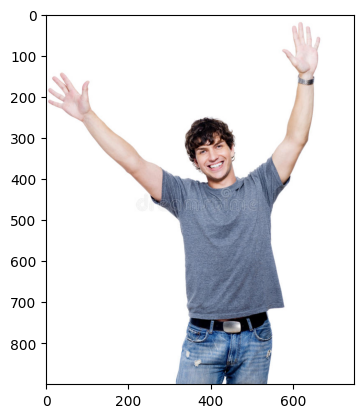

In [ ]:
# Lectura de una imagen y visualización
img = cv2.imread("pe_3.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img, cmap='Accent')
plt.show()

In [ ]:
# Tamaño de las imágenes
ANCHO = img.shape[1]
ALTO =img.shape[0]

In [ ]:
# Preprocesamiento de la imágen a través de blob from image
imgBlob = cv2.dnn.blobFromImage(img, scalefactor= 1.0 / 255, size=(368, 368), swapRB=True)
imgBlob.shape

(1, 3, 368, 368)

In [ ]:
# Generando una inferencia con el modelo
# El resultado contiene:
# (ID de la imagen, keypoints e affinity parts, height, width)

modelo.setInput(imgBlob)
output = modelo.forward()
output.shape

(1, 44, 46, 46)

Procesamiento de la salida del modelo

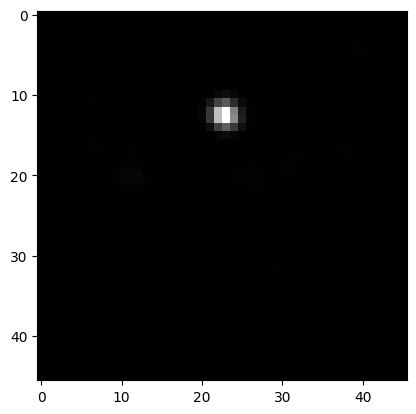

In [ ]:
# Análisis de la salida
plt.imshow(output[0, 0], cmap="gray")
plt.show()

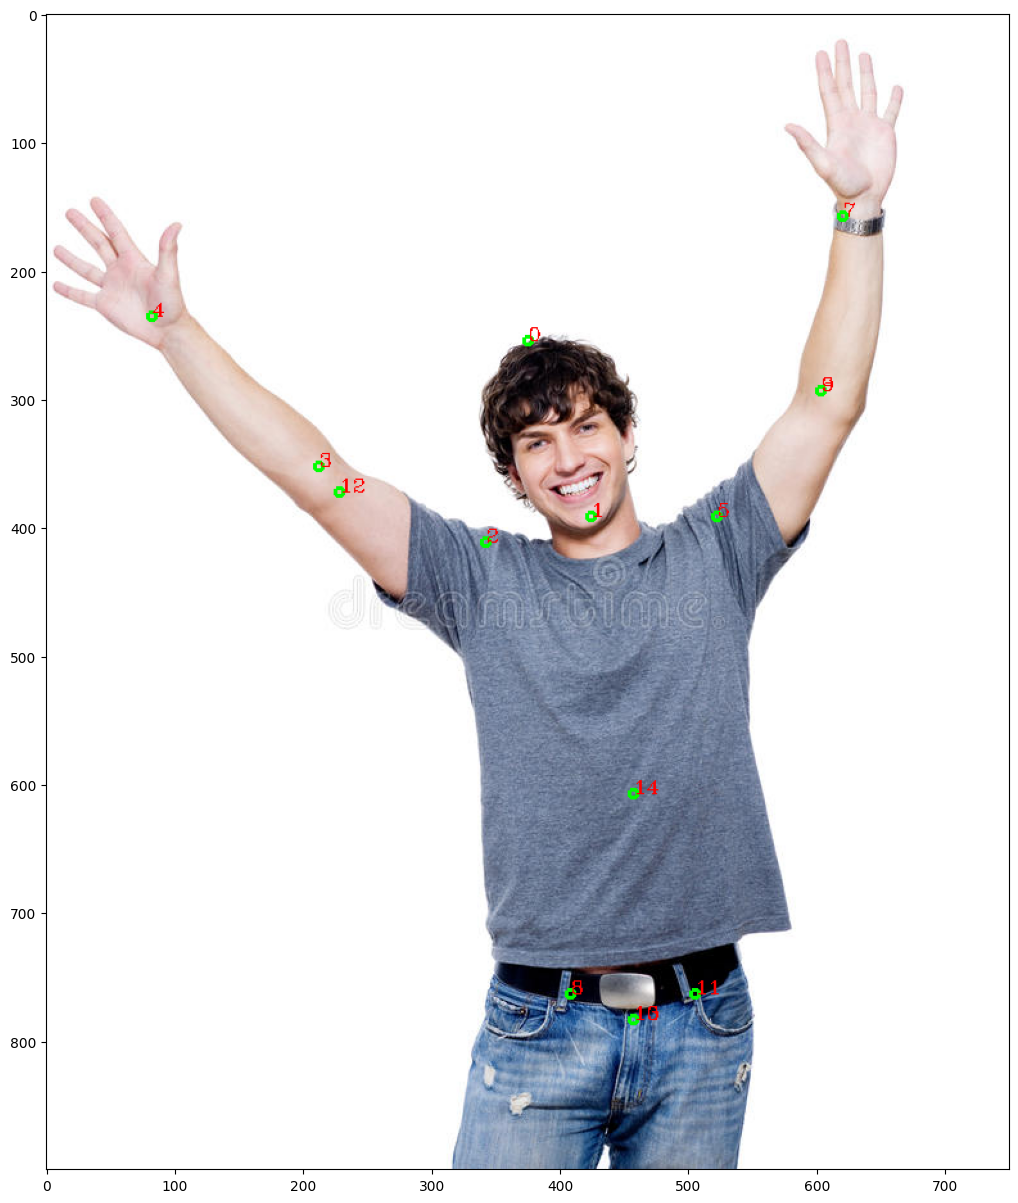

In [ ]:
h =   output.shape[3] # alto de la imágen de salida
w =   output.shape[2] # ancho de la imágen de salida

img_copy = np.copy(img)

for i in range(15):
  # Mapa con los scores de confianza de las partes del cuerpo:
  probMap = output[0, i, :, :]

  # Encontramos el máximo global del probMap.
  minV, maxV, minP, maxP = cv2.minMaxLoc(probMap)

  # Escalamos los puntos al tamaño original de la imágen
  x = round ((maxP[0] * ANCHO / w))
  y = round ((maxP[1] * ALTO / h))

  # Colocamos las anotaciones sobre la imágen
  cv2.circle(img_copy,(x,y),3,(0,255,0),2 )
  cv2.putText(img_copy, str(i), (x, y), cv2.FONT_HERSHEY_COMPLEX, 0.5, (255,0,0),1)


plt.figure(figsize=(15, 15))
plt.imshow(img_copy)
plt.show()

## Reto 1: detectar si la persona tiene las manos arriba

Tiene las manos arriba


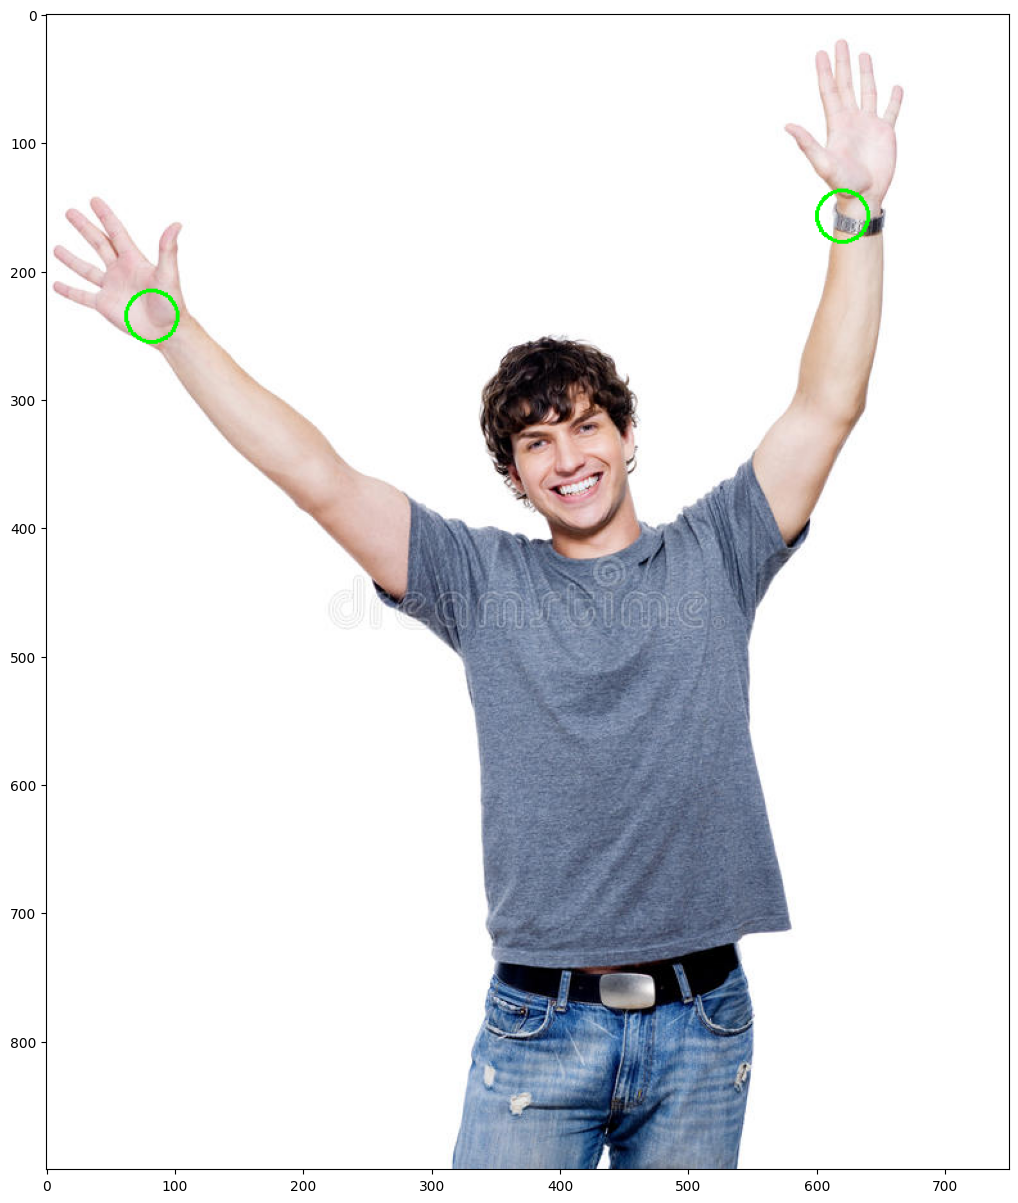

In [ ]:
# Estos son los puntos clave
# 0 - Cabeza
# 1 - Cuello
# 4 - Muñeca derecha
# 7 - Muñeca izquierda
puntosClave = [0, 1, 4, 7]
locPuntos = []

for i in puntosClave:
  probMap = output[0, i, :, :]
  minV, maxV, minP, maxP = cv2.minMaxLoc(probMap)
  h = output.shape[2]
  w = output.shape[3]
  x = round((ANCHO/w) * maxP[0])
  y = round((ALTO/h) * maxP[1])
  locPuntos.append((x,y))

# Validación de la postura de las manos
if locPuntos[2][1] < locPuntos[1][1]:
  color = (0, 255, 0)
  print("Tiene las manos arriba")
else:
  color = (0, 0, 255)
  print("No tiene las manos arriba")

# Visualización de los resultados
img_copy = np.copy(img)
cv2.circle(img_copy, (locPuntos[2][0], locPuntos[2][1]), 20, color, thickness=2)
cv2.circle(img_copy, (locPuntos[3][0], locPuntos[3][1]), 20, color, thickness=2)
plt.figure(figsize=(15, 15))
plt.imshow(img_copy)
plt.show()

## Reto 2: dibujar el esqueleto

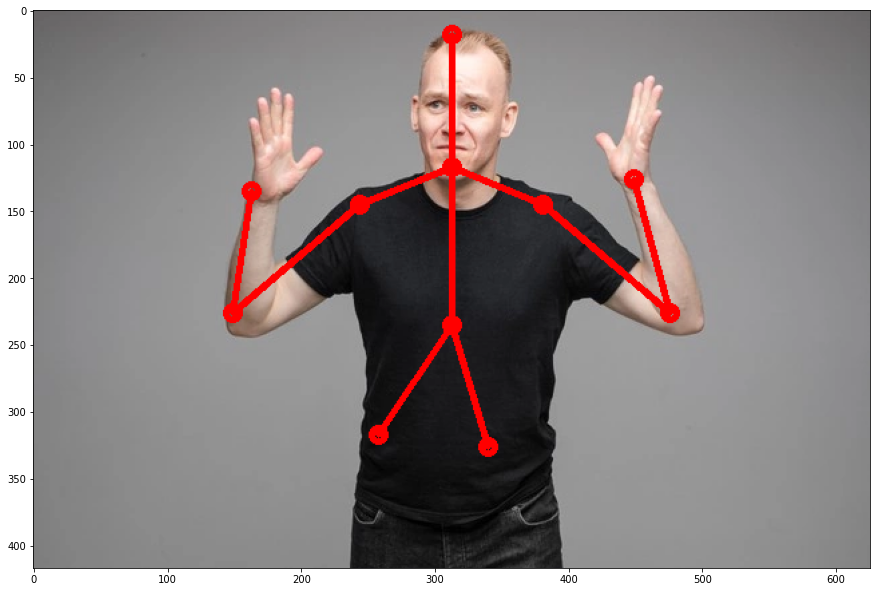